#### **IMPORTS**

In [6]:
import pandas as pd
import os

In [7]:
import pandas as pd
print(pd.__version__)  # should be 2.2.x

2.3.3


#### **LOAD**

In [8]:
import pickle
import os
from pandas.core.arrays.categorical import Categorical
from pandas._libs.arrays import NDArrayBacked

_orig_categorical_setstate = Categorical.__setstate__

def _patched_categorical_setstate(self, state):
    if not isinstance(state, dict):
        dtype, codes = state
        NDArrayBacked.__init__(self, codes, dtype)
    else:
        _orig_categorical_setstate(self, state)

Categorical.__setstate__ = _patched_categorical_setstate

In [9]:
DF_DIR = r"/ptmp/gongt/behaviour"

metadata_df = pd.read_pickle(os.path.join(DF_DIR, "metadata_df.pkl"))
texture_pca_df = pd.read_pickle(os.path.join(DF_DIR, "texture_pca_df_preproc.pkl"))

print(f"Texture PCA: {texture_pca_df.shape}")


Texture PCA: (2107089, 69)


In [10]:
print(metadata_df)

                            dataset collar   time background neural_prefix  \
0              GLC6512-20240705-001     no 0 days        NaN           NaN   
1           GLC6633-20241113-170117     no 0 days       eink          a_g1   
2           GLC6580-20241206-150207     no 0 days        NaN           NaN   
3           GLC6962-20250414-191607     no 0 days       eink          g_g0   
4              GLC6962-20250414-002     no 0 days       eink           NaN   
5              GLC6962-20250414-003     no 0 days       eink           NaN   
6              GLC6962-20250415-001     no 0 days    pebbles           NaN   
7           GLC6811-20250703-161334     no 0 days       eink            g2   
8           GLC6811-20250703-165741     no 0 days       eink            g3   
9           GLC7189-20250803-135836     no 0 days       eink          c_g0   
10          GLC6580-20241206-154230     no 0 days         3d          f_g1   
11          GLC6644-20241021-183656     no 0 days         3d    

In [11]:
sub = texture_pca_df[(texture_pca_df['animal'] == 'GLC6962') & (texture_pca_df['background'] == 'eink')]

print("=== GLC6962 eink — trial_idx=3 ===")
print(f"Number of ROWS (= video frames, not individual trials): {len(sub):,}")
print()

# trial_idx=3 is ONE continuous session — all frames belong to it
# Each row = one video frame at ~40 fps effective (every 3rd frame from 120fps camera)
tt = sub['trial_time'].dt.total_seconds()
abs_t = sub['time'].dt.total_seconds()
print(f"Session duration (trial_time): {tt.min():.4f} s  →  {tt.max():.4f} s")
print(f"Session duration (absolute)  : {abs_t.min():.4f} s  →  {abs_t.max():.4f} s")
print(f"  = {(tt.max() - tt.min()) / 60:.2f} min, {len(sub):,} frames at {len(sub)/(tt.max()-tt.min()):.2f} fps effective")
print()

# Show the first 10 rows
disp_cols = ['dataset', 'trial_idx', 'frame', 'trial_time', 'time', 'PC1']
disp_cols = [c for c in disp_cols if c in sub.columns]
print(f"First 10 rows (each row = one video frame):")
print(sub[disp_cols].head(10).to_string())

#time: from when SpikeGLX starts recording? step: 25ms
#trial_time: ??? 
#frame: original video frame index from the 120fps camera? (now divided by 3 since every 3rd frame is kept?) but then why 1.5, 2.5, etc.? idk? 

=== GLC6962 eink — trial_idx=3 ===
Number of ROWS (= video frames, not individual trials): 106,168

Session duration (trial_time): 0.0083 s  →  2654.9875 s
Session duration (absolute)  : 4.4709 s  →  2658.6459 s
  = 44.25 min, 106,168 frames at 39.99 fps effective

First 10 rows (each row = one video frame):
                        dataset  trial_idx     frame                trial_time                      time        PC1
277336  GLC6962-20250414-191607        3.0  0.333333 0 days 00:00:00.008333333 0 days 00:00:04.470910550 -15.040831
277337  GLC6962-20250414-191607        3.0  0.666667 0 days 00:00:00.016666666 0 days 00:00:04.495910550 -14.890210
277338  GLC6962-20250414-191607        3.0  1.500000    0 days 00:00:00.037500 0 days 00:00:04.520910550 -14.853350
277339  GLC6962-20250414-191607        3.0  2.500000    0 days 00:00:00.062500 0 days 00:00:04.545910550 -15.054943
277340  GLC6962-20250414-191607        3.0  3.500000    0 days 00:00:00.087500 0 days 00:00:04.570910550 -15.1

#### NEURAL DATA — GLC6962_g_g0

In [12]:
import numpy as np
import json
import spikeinterface as si

PREPROC_DIR = r"E:\GLC6962_g_g0\preprocessed"
PEAKS_FILE  = rf"{PREPROC_DIR}\thresholding_peaks\peaks_combined2.npy"
LOC_FILE    = rf"{PREPROC_DIR}\thresholding_peaks\localized_peaks_mt.npy"
META_FILE   = r"Z:\data\0_collaboration\ceph_phys\GLC6962\GLC6962_g_g0\GLC6962_g_g0_imec0\GLC6962_g_g0_t0.imec0.ap.meta"
# Note: sampling rate is also in PREPROC_DIR/binary.json, but the gate offset
# (firstSample — how far into recording the file starts) is only in the SpikeGLX .meta file.

# --- Sampling rate from binary.json ---
with open(rf"{PREPROC_DIR}\binary.json") as _f:
    _bj = json.load(_f)
ap_fs = float(_bj['kwargs']['sampling_frequency'])   # 30000.2835 Hz

# --- Gate offset from SpikeGLX AP meta ---
meta_ap = {}
with open(META_FILE) as _f:
    for _line in _f:
        _k, _, _v = _line.strip().partition('=')
        meta_ap[_k] = _v
ap_first_samp = int(meta_ap['firstSample'])   # 222446 samples elapsed from gate-open before file start
ap_t_offset   = ap_first_samp / ap_fs         # 7.415 s — file sample 0 is this far into the gate clock

# --- Custom peak detection: peaks_combined2 + localized_peaks_mt ---
peaks = np.load(PEAKS_FILE)    # structured: sample_index, channel_index, amplitude, segment_index, z
loc   = np.load(LOC_FILE)      # structured: x (lateral µm), y (depth µm), z (probe-normal µm), alpha

# peaks['amplitude'] is negative (threshold crossings) — take abs for downstream use
spike_times_samp = peaks['sample_index']    # int64: sample index in file
spike_amp        = np.abs(peaks['amplitude']).astype(np.float32)  # µV magnitude
spike_x          = loc['x'].astype(np.float32)   # lateral µm
spike_z          = loc['y'].astype(np.float32)   # depth along probe µm  (field is 'y' in localized file)

# Convert to gate-relative seconds — same clock as texture_pca_df['time']
spike_t_gate = spike_times_samp / ap_fs + ap_t_offset

# --- Behavioral subset for this session ---
beh     = texture_pca_df[(texture_pca_df['animal'] == 'GLC6962') & (texture_pca_df['background'] == 'eink')].copy()
beh_t   = beh['time'].dt.total_seconds().values   # gate-relative seconds
beh_pc1 = beh['PC1'].values
beh_spd = beh['speed'].values if 'speed' in beh.columns else None

print(f"AP sampling rate    : {ap_fs:.4f} Hz  (from binary.json)")
print(f"Gate offset         : {ap_t_offset:.3f} s  (firstSample={ap_first_samp} from .meta)")
print(f"Total peaks         : {len(spike_t_gate):,}")
print(f"spike_t_gate range  : {spike_t_gate.min():.2f} – {spike_t_gate.max():.2f} s")
print(f"x range (lateral)   : {spike_x.min():.1f} – {spike_x.max():.1f} µm")
print(f"z range (depth)     : {spike_z.min():.1f} – {spike_z.max():.1f} µm")
print(f"amplitude range     : {spike_amp.min():.2f} – {spike_amp.max():.2f} µV")
print(f"\nBehavioral rows     : {len(beh_t):,}")
print(f"beh_t range         : {beh_t.min():.3f} – {beh_t.max():.3f} s")
print(f"Neural–video offset : neural starts {ap_t_offset - beh_t.min():.3f} s AFTER video")


/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FileNotFoundError: [Errno 2] No such file or directory: 'E:\\GLC6962_g_g0\\preprocessed\\binary.json'

#### ALIGNMENT CHECK

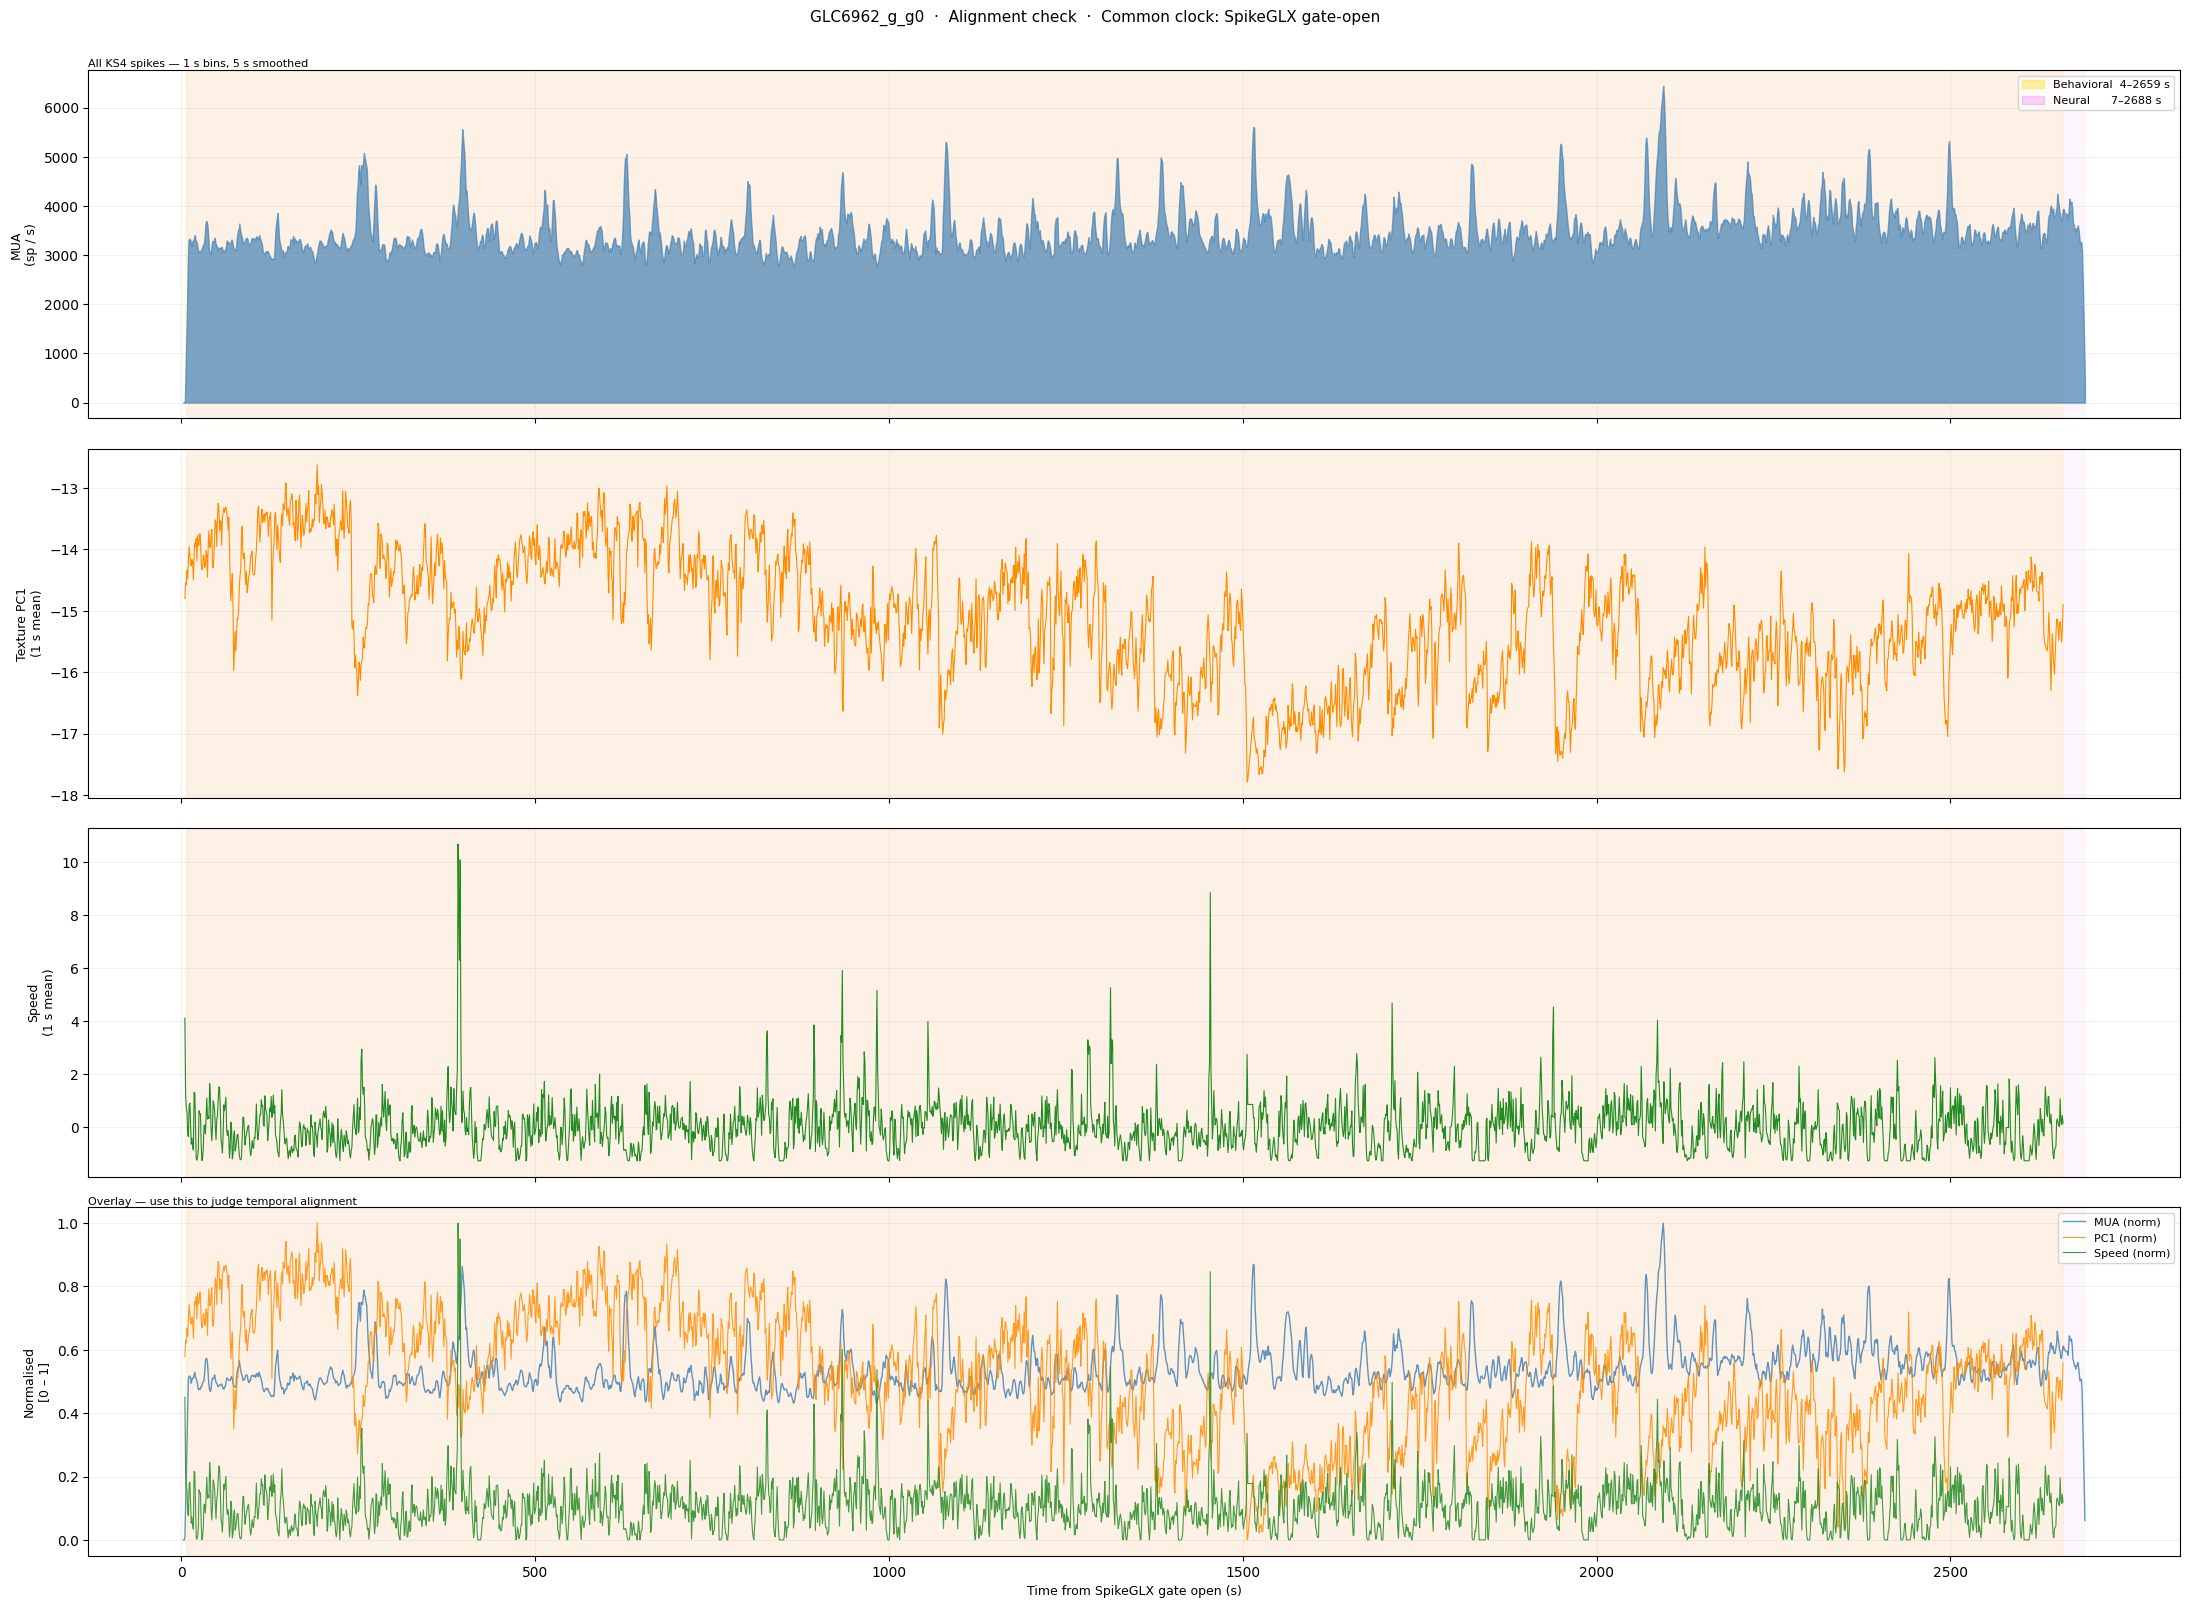

Behavioral window : 4.471 – 2658.646 s  (44.24 min)
Neural window     : 7.415 – 2687.992 s  (44.68 min)
Overlap           : 7.415 – 2658.646 s  (44.19 min)
Neural starts 2.944 s after video (gate-relative offset)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy.ndimage import uniform_filter1d

# ── 1. Bin MUA into 1-second windows (gate-relative time) ──────────────────
BIN_ALIGN  = 1.0   # seconds
t_lo = min(spike_t_gate.min(), beh_t.min()) - 2
t_hi = max(spike_t_gate.max(), beh_t.max()) + 2
bins_1s  = np.arange(t_lo, t_hi + BIN_ALIGN, BIN_ALIGN)
t_ctr    = (bins_1s[:-1] + bins_1s[1:]) / 2

mua_counts, _ = np.histogram(spike_t_gate, bins=bins_1s)
mua_hz = uniform_filter1d(mua_counts.astype(float) / BIN_ALIGN, size=5)  # 5 s smoothing

# ── 2. Bin behavioral signals into same windows ─────────────────────────────
def bin_signal(t_arr, sig, bins):
    out = np.full(len(bins) - 1, np.nan)
    for i in range(len(bins) - 1):
        m = (t_arr >= bins[i]) & (t_arr < bins[i + 1])
        if m.any():
            out[i] = np.nanmean(sig[m])
    return out

pc1_1s = bin_signal(beh_t, beh_pc1, bins_1s)
spd_1s = bin_signal(beh_t, beh_spd, bins_1s) if beh_spd is not None else None

# ── 3. Build normalised overlay ─────────────────────────────────────────────
def norm01(x):
    mn, mx = np.nanmin(x), np.nanmax(x)
    return (x - mn) / (mx - mn + 1e-9)

# ── 4. Plot ──────────────────────────────────────────────────────────────────
n_rows = 2 + (spd_1s is not None)
fig, axes = plt.subplots(n_rows + 1, 1, figsize=(22, 4 * (n_rows + 1)), sharex=True)
fig.suptitle(
    "GLC6962_g_g0  ·  Alignment check  ·  Common clock: SpikeGLX gate-open",
    fontsize=11, y=1.002
)

# Row 0: MUA firing rate
axes[0].fill_between(t_ctr, mua_hz, alpha=0.7, color='steelblue')
axes[0].set_ylabel("MUA\n(sp / s)", fontsize=9)
axes[0].set_title("All KS4 spikes — 1 s bins, 5 s smoothed", fontsize=8, loc='left', pad=2)

# Row 1: texture PC1
axes[1].plot(t_ctr, pc1_1s, color='darkorange', lw=0.8)
axes[1].set_ylabel("Texture PC1\n(1 s mean)", fontsize=9)

row = 2
if spd_1s is not None:
    axes[row].plot(t_ctr, spd_1s, color='forestgreen', lw=0.8)
    axes[row].set_ylabel("Speed\n(1 s mean)", fontsize=9)
    row += 1

# Last row: normalised overlay to check temporal match
ax_ov = axes[row]
ax_ov.plot(t_ctr, norm01(mua_hz),  color='steelblue',   lw=1.0, alpha=0.85, label='MUA (norm)')
ax_ov.plot(t_ctr, norm01(pc1_1s),  color='darkorange',  lw=0.8, alpha=0.85, label='PC1 (norm)')
if spd_1s is not None:
    ax_ov.plot(t_ctr, norm01(spd_1s), color='forestgreen', lw=0.8, alpha=0.85, label='Speed (norm)')
ax_ov.set_ylabel("Normalised\n[0 – 1]", fontsize=9)
ax_ov.legend(fontsize=8, loc='upper right')
ax_ov.set_title("Overlay — use this to judge temporal alignment", fontsize=8, loc='left', pad=2)

# Shade windows on every axis
beh_patch = mpatches.Patch(color='gold',   alpha=0.35, label=f"Behavioral  {beh_t.min():.0f}–{beh_t.max():.0f} s")
neu_patch = mpatches.Patch(color='violet', alpha=0.35, label=f"Neural      {ap_t_offset:.0f}–{spike_t_gate.max():.0f} s")
for ax in axes:
    ax.axvspan(beh_t.min(),   beh_t.max(),        color='gold',   alpha=0.10, zorder=0)
    ax.axvspan(ap_t_offset,   spike_t_gate.max(), color='violet', alpha=0.08, zorder=0)
    ax.grid(True, alpha=0.25, lw=0.5)

axes[0].legend(handles=[beh_patch, neu_patch], fontsize=8, loc='upper right')
axes[-1].set_xlabel("Time from SpikeGLX gate open (s)", fontsize=9)

plt.tight_layout()
plt.show()

# ── 5. Summary ───────────────────────────────────────────────────────────────
beh_dur = beh_t.max() - beh_t.min()
neu_dur = spike_t_gate.max() - ap_t_offset
ov_lo   = max(beh_t.min(), ap_t_offset)
ov_hi   = min(beh_t.max(), spike_t_gate.max())
print(f"Behavioral window : {beh_t.min():.3f} – {beh_t.max():.3f} s  ({beh_dur/60:.2f} min)")
print(f"Neural window     : {ap_t_offset:.3f} – {spike_t_gate.max():.3f} s  ({neu_dur/60:.2f} min)")
print(f"Overlap           : {ov_lo:.3f} – {ov_hi:.3f} s  ({(ov_hi-ov_lo)/60:.2f} min)")
print(f"Neural starts {ap_t_offset - beh_t.min():.3f} s after video (gate-relative offset)")


In [5]:
import numpy as np

TTL_FILE = r"Z:\data\0_collaboration\ceph_phys\GLC6962\GLC6962_g_g0\ttl_overview_on.txt"

# Load TTL pulse times — recorded by SpikeGLX on the same gate clock as spike_t_gate
with open(TTL_FILE) as _f:
    ttl = np.array(_f.read().strip().split(','), dtype=np.float64)

print(ttl.shape)
print(beh_t.shape)

print(ttl[:5])
print(beh_t[:5])

print(ttl[-5:-1])
print(beh_t[-5:-1])

FileNotFoundError: [Errno 2] No such file or directory: 'Z:\\data\\0_collaboration\\ceph_phys\\GLC6962\\GLC6962_g_g0\\ttl_overview_on.txt'

#### SPIKE POSITION VISUALISATION

C:\Users\gongt\AppData\Local\Temp\ipykernel_22904\1028243463.py:11: DeprecationWarning: load_extractor() is deprecated and will be removed in version 0.104.0. Please use load() instead.
  rec_si = si.load_extractor(PREPROC_DIR)


Channels: 355   probe x: 0.0 – 48.0 µm   depth: 0 – 3820 µm
Spikes in 50 ms window : 263
  outside probe x range           : 200  (76%)


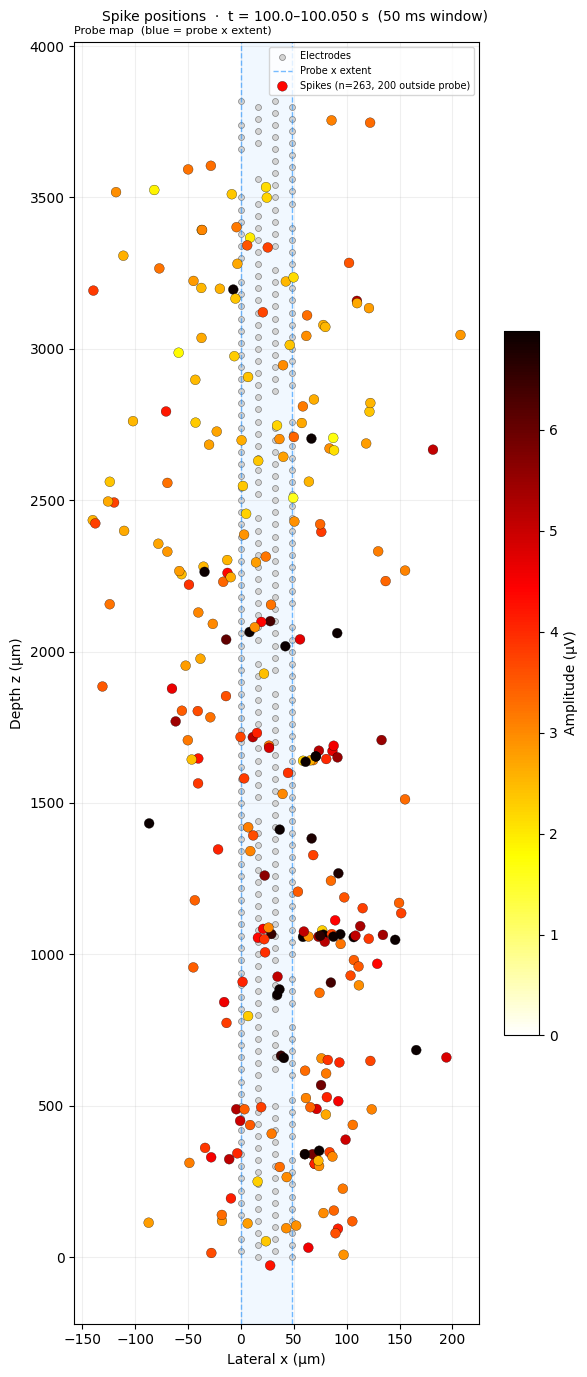

In [ ]:

# ── SPIKE x/z SCATTER + ELECTRODE MAP ─────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

# ── Parameters — adjust to inspect different parts of the recording ───────────
T_START = 100.0   # gate-relative start of window (s)
T_WIN   = 0.05    # window width (s)

# ── Load channel positions from the spikeinterface saved recording ─────────────
try:
    rec_si = si.load_extractor(PREPROC_DIR)
except Exception:
    import spikeinterface.core as _sc
    rec_si = _sc.load_extractor(PREPROC_DIR)
ch_locs      = rec_si.get_channel_locations()   # (n_ch, 2): [x µm, depth µm]
probe_x_min  = ch_locs[:, 0].min()
probe_x_max  = ch_locs[:, 0].max()
print(f"Channels: {rec_si.get_num_channels()}   "
      f"probe x: {probe_x_min:.1f} – {probe_x_max:.1f} µm   "
      f"depth: {ch_locs[:,1].min():.0f} – {ch_locs[:,1].max():.0f} µm")

# ── Spike selection ────────────────────────────────────────────────────────────
mask    = (spike_t_gate >= T_START) & (spike_t_gate < T_START + T_WIN)
sx, sz, sa = spike_x[mask], spike_z[mask], spike_amp[mask]
outside = (sx < probe_x_min) | (sx > probe_x_max)
print(f"Spikes in {T_WIN*1e3:.0f} ms window : {mask.sum()}")
print(f"  outside probe x range           : {outside.sum()}  ({outside.mean()*100:.0f}%)")

# ── Plot — single panel ────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 14))
fig.suptitle(f"Spike positions  ·  t = {T_START}–{T_START+T_WIN:.3f} s  ({T_WIN*1e3:.0f} ms window)",
             fontsize=10)

ax.scatter(ch_locs[:, 0], ch_locs[:, 1], s=18, c='lightgray',
           edgecolors='gray', linewidths=0.5, zorder=2, label='Electrodes')
ax.axvspan(probe_x_min, probe_x_max, color='dodgerblue', alpha=0.06, zorder=0)
ax.axvline(probe_x_min, color='dodgerblue', lw=1, alpha=0.6, ls='--', label='Probe x extent')
ax.axvline(probe_x_max, color='dodgerblue', lw=1, alpha=0.6, ls='--')
if mask.any():
    amp_vmax = np.percentile(spike_amp, 95)
    sc_h = ax.scatter(sx, sz, c=sa, s=50, cmap='hot_r',
                      vmin=0, vmax=amp_vmax,
                      edgecolors='k', linewidths=0.2, zorder=5,
                      label=f'Spikes (n={mask.sum()}, {outside.sum()} outside probe)')
    plt.colorbar(sc_h, ax=ax, label='Amplitude (µV)', shrink=0.55)
ax.set_xlabel('Lateral x (µm)')
ax.set_ylabel('Depth z (µm)')
ax.set_title('Probe map  (blue = probe x extent)', fontsize=8, loc='left')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


High-amp spikes: 28–43 µV
Low-amp  spikes: 0–1 µV


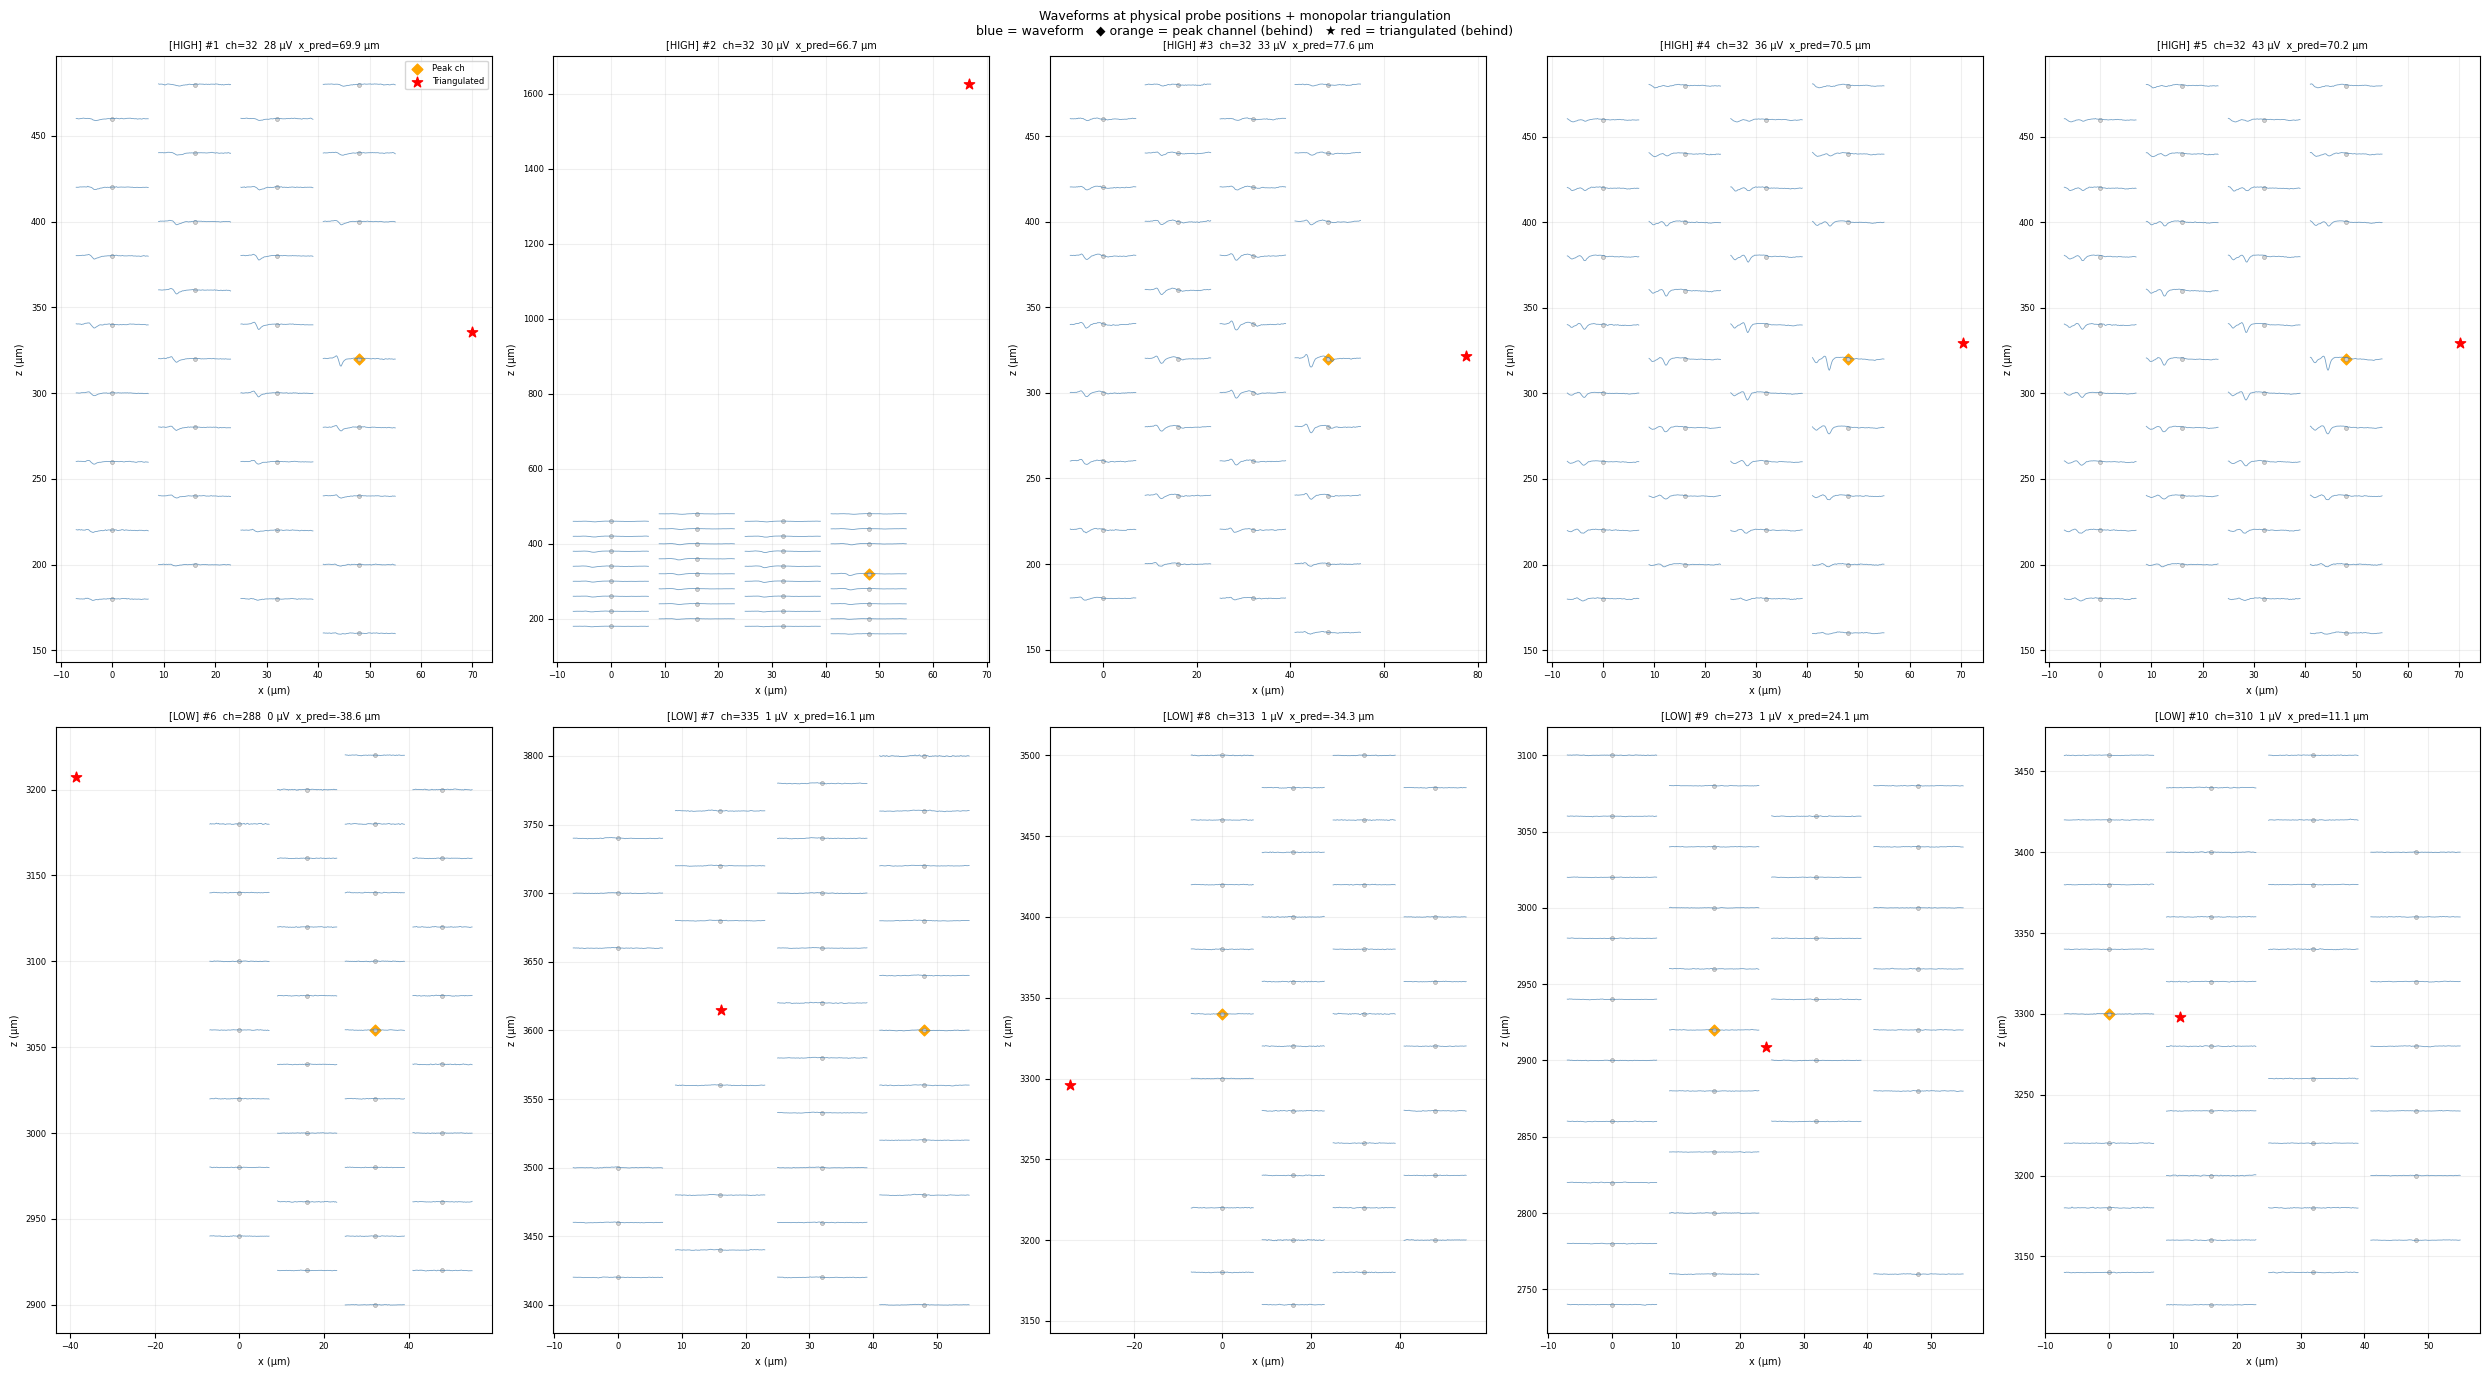

In [ ]:

# ── WAVEFORMS AT PROBE POSITIONS + TRIANGULATED LOCATION ──────────────────────
# Requires rec_si / ch_locs from scatter cell above.
import matplotlib.pyplot as plt
import numpy as np

# ── Parameters ────────────────────────────────────────────────────────────────
T_POOL_START = 100.0    # pool spikes from this time range (s, gate-relative)
T_POOL_END   = 110.0
N_HIGH       = 5        # top-amplitude spikes to show
N_LOW        = 5        # bottom-amplitude spikes to show
N_BEFORE     = 20       # samples before trough
N_AFTER      = 62       # samples after trough  (~2.7 ms @ 30 kHz)
N_NBR        = 32       # nearest channels to overlay
WF_WIDTH_UM  = 14       # horizontal span of one waveform in probe-space µm
AMP_SCALE    = 0.15     # vertical scale: µm per µV

# ── Pick 5 high-amplitude + 5 low-amplitude spikes ────────────────────────────
mask      = (spike_t_gate >= T_POOL_START) & (spike_t_gate < T_POOL_END)
cands     = np.where(mask)[0]
amp_order = np.argsort(spike_amp[cands])
sel_low   = cands[amp_order[:N_LOW]]      # weakest N_LOW
sel_high  = cands[amp_order[-N_HIGH:]]    # strongest N_HIGH
sel       = np.concatenate([sel_high, sel_low])   # high first, then low
N_SPIKES  = len(sel)
print(f"High-amp spikes: {spike_amp[sel_high].min():.0f}–{spike_amp[sel_high].max():.0f} µV")
print(f"Low-amp  spikes: {spike_amp[sel_low].min():.0f}–{spike_amp[sel_low].max():.0f} µV")

t_um         = np.linspace(-WF_WIDTH_UM / 2, WF_WIDTH_UM / 2, N_BEFORE + N_AFTER)
wf_len       = N_BEFORE + N_AFTER
n_total_samp = rec_si.get_num_samples()

# ── Plot ───────────────────────────────────────────────────────────────────────
ncols = 5
nrows = int(np.ceil(N_SPIKES / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 7))
axes = np.array(axes).flatten()
fig.suptitle(
    "Waveforms at physical probe positions + monopolar triangulation\n"
    "blue = waveform   ◆ orange = peak channel (behind)   ★ red = triangulated (behind)",
    fontsize=9)

for plot_i, spike_i in enumerate(sel):
    ax     = axes[plot_i]
    samp   = int(spike_times_samp[spike_i])
    pk_ch  = int(peaks['channel_index'][spike_i])
    pred_x = float(spike_x[spike_i])
    pred_z = float(spike_z[spike_i])

    # Nearest channels by probe distance
    dists = np.linalg.norm(ch_locs - ch_locs[pk_ch], axis=1)
    nbr   = np.argsort(dists)[:N_NBR]

    # Read traces from the binary recording
    t0_s = max(0, samp - N_BEFORE)
    t1_s = min(n_total_samp, samp + N_AFTER)
    tr   = rec_si.get_traces(start_frame=t0_s, end_frame=t1_s)[:, nbr]
    if tr.shape[0] < wf_len:
        tr = np.pad(tr, ((0, wf_len - tr.shape[0]), (0, 0)))

    # ── Symbols drawn first (behind waveforms, zorder=2) ──────────────────────
    pk_x, pk_y = ch_locs[pk_ch, 0], ch_locs[pk_ch, 1]
    ax.scatter(pk_x, pk_y, s=30, c='orange', marker='D', zorder=2,
               label='Peak ch' if plot_i == 0 else None)
    ax.scatter(pred_x, pred_z, s=60, c='red', marker='*', zorder=2,
               label='Triangulated' if plot_i == 0 else None)

    # ── Waveforms drawn on top (zorder=3/4) ────────────────────────────────────
    for j, ch_j in enumerate(nbr):
        xc, yc = ch_locs[ch_j, 0], ch_locs[ch_j, 1]
        ax.scatter(xc, yc, s=8, c='lightgray', edgecolors='gray',
                   linewidths=0.3, zorder=3)
        ax.plot(xc + t_um, yc + tr[:, j] * AMP_SCALE,
                lw=0.6, color='steelblue', alpha=0.75, zorder=4)

    group = 'HIGH' if plot_i < N_HIGH else 'LOW'
    ax.set_title(
        f"[{group}] #{plot_i+1}  ch={pk_ch}  {spike_amp[spike_i]:.0f} µV  "
        f"x_pred={pred_x:.1f} µm",
        fontsize=7)
    ax.set_xlabel('x (µm)', fontsize=7)
    ax.set_ylabel('z (µm)', fontsize=7)
    ax.tick_params(labelsize=6)
    ax.grid(True, alpha=0.2)
    if plot_i == 0:
        ax.legend(fontsize=6, loc='upper right')

for ax in axes[N_SPIKES:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


#### SPIKE FEATURES FOR DENSITY DECODING